___

<a href='http://www.pieriandata.com'> <img src='../Pierian_Data_Logo.png' /></a>
___
# Random Forest Project

For this project we will be exploring publicly available data from [LendingClub.com](www.lendingclub.com). Lending Club connects people who need money (borrowers) with people who have money (investors). Hopefully, as an investor you would want to invest in people who showed a profile of having a high probability of paying you back. We will try to create a model that will help predict this.

Lending club had a [very interesting year in 2016](https://en.wikipedia.org/wiki/Lending_Club#2016), so let's check out some of their data and keep the context in mind. This data is from before they even went public.

We will use lending data from 2007-2010 and be trying to classify and predict whether or not the borrower paid back their loan in full. You can download the data from [here](https://www.lendingclub.com/info/download-data.action) or just use the csv already provided. It's recommended you use the csv provided as it has been cleaned of NA values.

Here are what the columns represent:
* credit.policy: 1 if the customer meets the credit underwriting criteria of LendingClub.com, and 0 otherwise.
* purpose: The purpose of the loan (takes values "credit_card", "debt_consolidation", "educational", "major_purchase", "small_business", and "all_other").
* int.rate: The interest rate of the loan, as a proportion (a rate of 11% would be stored as 0.11). Borrowers judged by LendingClub.com to be more risky are assigned higher interest rates.
* installment: The monthly installments owed by the borrower if the loan is funded.
* log.annual.inc: The natural log of the self-reported annual income of the borrower.
* dti: The debt-to-income ratio of the borrower (amount of debt divided by annual income).
* fico: The FICO credit score of the borrower.
* days.with.cr.line: The number of days the borrower has had a credit line.
* revol.bal: The borrower's revolving balance (amount unpaid at the end of the credit card billing cycle).
* revol.util: The borrower's revolving line utilization rate (the amount of the credit line used relative to total credit available).
* inq.last.6mths: The borrower's number of inquiries by creditors in the last 6 months.
* delinq.2yrs: The number of times the borrower had been 30+ days past due on a payment in the past 2 years.
* pub.rec: The borrower's number of derogatory public records (bankruptcy filings, tax liens, or judgments).

# Import Libraries

**Import the usual libraries for pandas and plotting. You can import sklearn later on.**

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

## Get the Data

** Use pandas to read loan_data.csv as a dataframe called loans.**

In [ ]:
loans=pd.read_csv('/content/loan_data 1.csv')

** Check out the info(), head(), and describe() methods on loans.**

In [ ]:
loans.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9578 entries, 0 to 9577
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   credit.policy      9578 non-null   int64  
 1   purpose            9578 non-null   object 
 2   int.rate           9578 non-null   float64
 3   installment        9578 non-null   float64
 4   log.annual.inc     9578 non-null   float64
 5   dti                9578 non-null   float64
 6   fico               9578 non-null   int64  
 7   days.with.cr.line  9578 non-null   float64
 8   revol.bal          9578 non-null   int64  
 9   revol.util         9578 non-null   float64
 10  inq.last.6mths     9578 non-null   int64  
 11  delinq.2yrs        9578 non-null   int64  
 12  pub.rec            9578 non-null   int64  
 13  not.fully.paid     9578 non-null   int64  
dtypes: float64(6), int64(7), object(1)
memory usage: 1.0+ MB


In [ ]:
loans.describe()

,credit.policy,int.rate,installment,log.annual.inc,dti,fico,days.with.cr.line,revol.bal,revol.util,inq.last.6mths,delinq.2yrs,pub.rec,not.fully.paid
count,9578.000000,9578.000000,9578.000000,9578.000000,9578.000000,9578.000000,9578.000000,9.578000e+03,9578.000000,9578.000000,9578.000000,9578.000000,9578.000000
mean,0.804970,0.122640,319.089413,10.932117,12.606679,710.846314,4560.767197,1.691396e+04,46.799236,1.577469,0.163708,0.062122,0.160054
std,0.396245,0.026847,207.071301,0.614813,6.883970,37.970537,2496.930377,3.375619e+04,29.014417,2.200245,0.546215,0.262126,0.366676
min,0.000000,0.060000,15.670000,7.547502,0.000000,612.000000,178.958333,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000
25%,1.000000,0.103900,163.770000,10.558414,7.212500,682.000000,2820.000000,3.187000e+03,22.600000,0.000000,0.000000,0.000000,0.000000
50%,1.000000,0.122100,268.950000,10.928884,12.665000,707.000000,4139.958333,8.596000e+03,46.300000,1.000000,0.000000,0.000000,0.000000
75%,1.000000,0.140700,432.762500,11.291293,17.950000,737.000000,5730.000000,1.824950e+04,70.900000,2.000000,0.000000,0.000000,0.000000
max,1.000000,0.216400,940.140000,14.528354,29.960000,827.000000,17639.958330,1.207359e+06,119.000000,33.000000,13.000000,5.000000,1.000000


In [ ]:
loans.head()

,credit.policy,purpose,int.rate,installment,log.annual.inc,dti,fico,days.with.cr.line,revol.bal,revol.util,inq.last.6mths,delinq.2yrs,pub.rec,not.fully.paid
0,1,debt_consolidation,0.1189,829.10,11.350407,19.48,737,5639.958333,28854,52.1,0,0,0,0
1,1,credit_card,0.1071,228.22,11.082143,14.29,707,2760.000000,33623,76.7,0,0,0,0
2,1,debt_consolidation,0.1357,366.86,10.373491,11.63,682,4710.000000,3511,25.6,1,0,0,0
3,1,debt_consolidation,0.1008,162.34,11.350407,8.10,712,2699.958333,33667,73.2,1,0,0,0
4,1,credit_card,0.1426,102.92,11.299732,14.97,667,4066.000000,4740,39.5,0,1,0,0


# Exploratory Data Analysis

Let's do some data visualization! We'll use seaborn and pandas built-in plotting capabilities, but feel free to use whatever library you want. Don't worry about the colors matching, just worry about getting the main idea of the plot.

** Create a histogram of two FICO distributions on top of each other, one for each credit.policy outcome.**

*Note: This is pretty tricky, feel free to reference the solutions. You'll probably need one line of code for each histogram, I also recommend just using pandas built in .hist()*

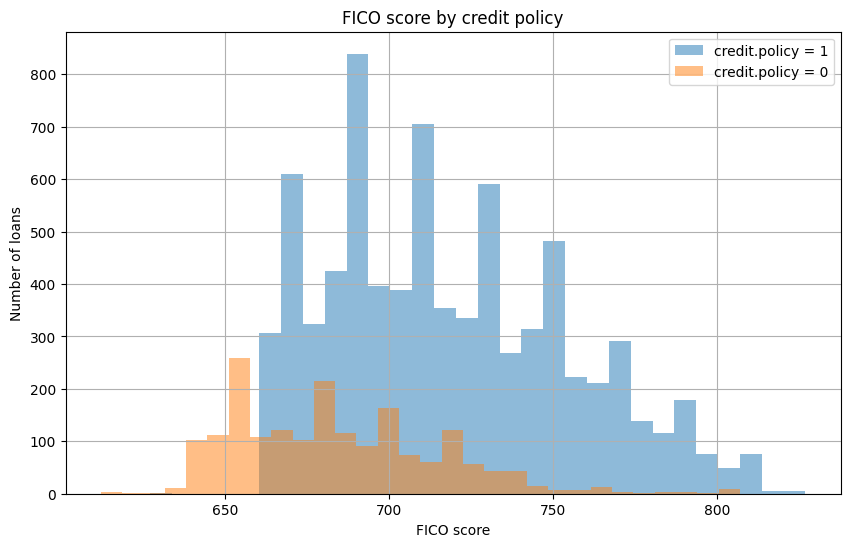

In [ ]:
plt.figure(figsize=(10, 6))
loans.loc[loans['credit.policy'] == 1, 'fico'].hist(alpha=0.5, bins=30, label='credit.policy = 1')
loans.loc[loans['credit.policy'] == 0, 'fico'].hist(alpha=0.5, bins=30, label='credit.policy = 0')
plt.xlabel('FICO score')
plt.ylabel('Number of loans')
plt.title('FICO score by credit policy')
plt.legend()
plt.show()

** Create a similar figure, except this time select by the not.fully.paid column.**

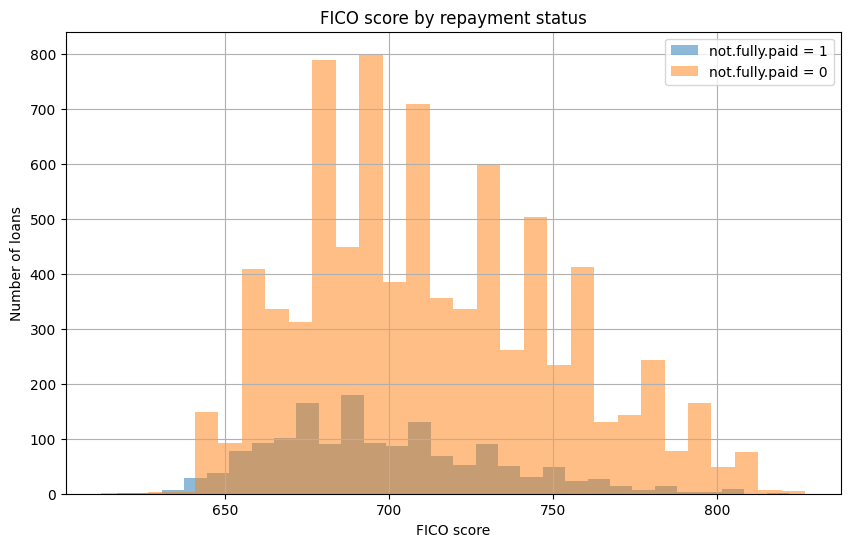

In [ ]:
plt.figure(figsize=(10, 6))
loans.loc[loans['not.fully.paid'] == 1, 'fico'].hist(alpha=0.5, bins=30, label='not.fully.paid = 1')
loans.loc[loans['not.fully.paid'] == 0, 'fico'].hist(alpha=0.5, bins=30, label='not.fully.paid = 0')
plt.xlabel('FICO score')
plt.ylabel('Number of loans')
plt.title('FICO score by repayment status')
plt.legend()
plt.show()

** Create a countplot using seaborn showing the counts of loans by purpose, with the color hue defined by not.fully.paid. **

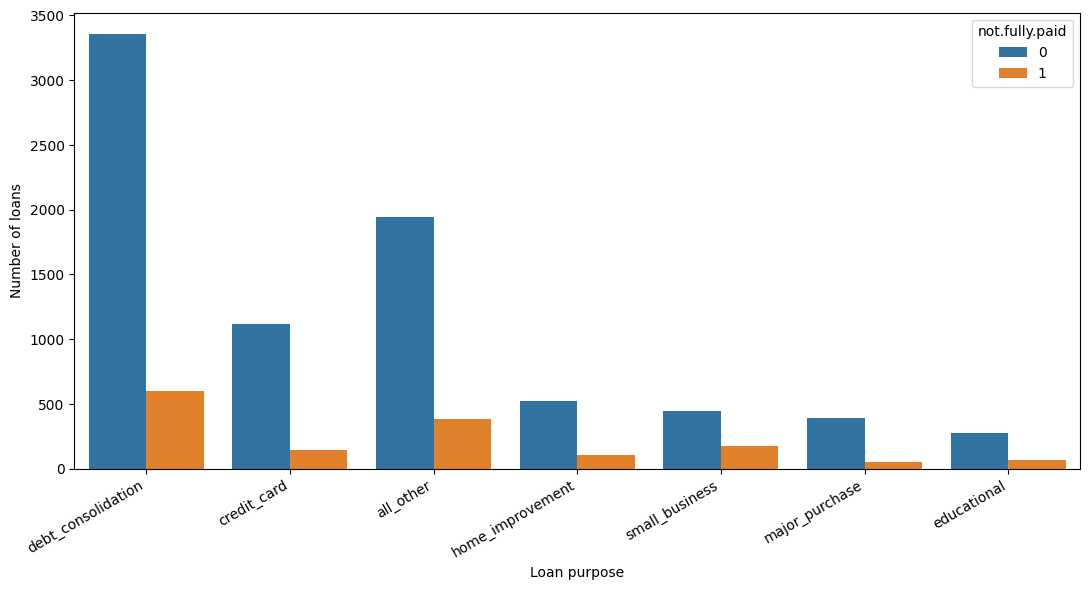

In [ ]:
plt.figure(figsize=(11, 6))
sns.countplot(data=loans, x='purpose', hue='not.fully.paid')
plt.xlabel('Loan purpose')
plt.ylabel('Number of loans')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.show()

** Let's see the trend between FICO score and interest rate. Recreate the following jointplot.**

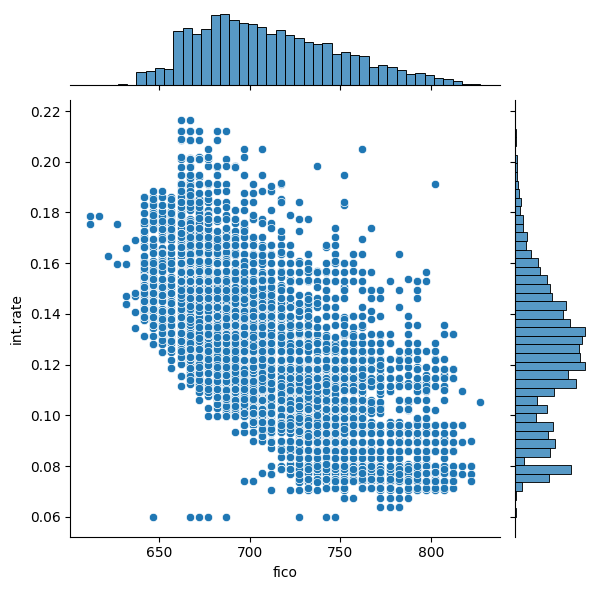

In [ ]:
sns.jointplot(data=loans, x='fico', y='int.rate', kind='scatter')
plt.show()

** Create the following lmplots to see if the trend differed between not.fully.paid and credit.policy. Check the documentation for lmplot() if you can't figure out how to separate it into columns.**

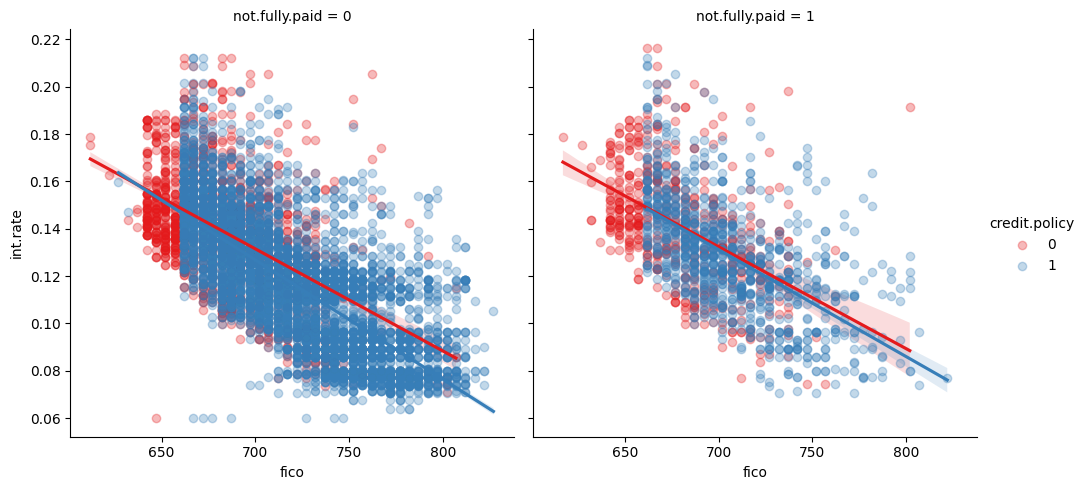

In [ ]:
sns.lmplot(
    data=loans,
    x='fico',
    y='int.rate',
    col='not.fully.paid',
    hue='credit.policy',
    palette='Set1',
    scatter_kws={'alpha': 0.3}
)
plt.show()

# Setting up the Data

Let's get ready to set up our data for our Random Forest Classification Model!

**Check loans.info() again.**

In [ ]:
loans.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9578 entries, 0 to 9577
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   credit.policy      9578 non-null   int64  
 1   purpose            9578 non-null   object 
 2   int.rate           9578 non-null   float64
 3   installment        9578 non-null   float64
 4   log.annual.inc     9578 non-null   float64
 5   dti                9578 non-null   float64
 6   fico               9578 non-null   int64  
 7   days.with.cr.line  9578 non-null   float64
 8   revol.bal          9578 non-null   int64  
 9   revol.util         9578 non-null   float64
 10  inq.last.6mths     9578 non-null   int64  
 11  delinq.2yrs        9578 non-null   int64  
 12  pub.rec            9578 non-null   int64  
 13  not.fully.paid     9578 non-null   int64  
dtypes: float64(6), int64(7), object(1)
memory usage: 1.0+ MB


## Categorical Features

Notice that the **purpose** column as categorical

That means we need to transform them using dummy variables so sklearn will be able to understand them. Let's do this in one clean step using pd.get_dummies.

Let's show you a way of dealing with these columns that can be expanded to multiple categorical features if necessary.

**Create a list of 1 element containing the string 'purpose'. Call this list cat_feats.**

In [ ]:
cat_feats=['purpose']

**Now use pd.get_dummies(loans,columns=cat_feats,drop_first=True) to create a fixed larger dataframe that has new feature columns with dummy variables. Set this dataframe as final_data.**

In [ ]:
final_data = pd.get_dummies(loans, columns=cat_feats, drop_first=True)

In [ ]:
final_data.head()

,credit.policy,int.rate,installment,log.annual.inc,dti,fico,days.with.cr.line,revol.bal,revol.util,inq.last.6mths,delinq.2yrs,pub.rec,not.fully.paid,purpose_credit_card,purpose_debt_consolidation,purpose_educational,purpose_home_improvement,purpose_major_purchase,purpose_small_business
0,1,0.1189,829.10,11.350407,19.48,737,5639.958333,28854,52.1,0,0,0,0,False,True,False,False,False,False
1,1,0.1071,228.22,11.082143,14.29,707,2760.000000,33623,76.7,0,0,0,0,True,False,False,False,False,False
2,1,0.1357,366.86,10.373491,11.63,682,4710.000000,3511,25.6,1,0,0,0,False,True,False,False,False,False
3,1,0.1008,162.34,11.350407,8.10,712,2699.958333,33667,73.2,1,0,0,0,False,True,False,False,False,False
4,1,0.1426,102.92,11.299732,14.97,667,4066.000000,4740,39.5,0,1,0,0,True,False,False,False,False,False


## Train Test Split

Now its time to split our data into a training set and a testing set!

** Use sklearn to split your data into a training set and a testing set as we've done in the past.**

In [ ]:
from sklearn.model_selection import train_test_split

X = final_data.drop('not.fully.paid', axis=1)
y = final_data['not.fully.paid']

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=101
)
print(f'Train rows: {len(X_train):,}; test rows: {len(X_test):,}')

Train rows: 6,704; test rows: 2,874


## Training a Decision Tree Model

Let's start by training a single decision tree first!

** Import DecisionTreeClassifier**

In [ ]:
from sklearn.tree import DecisionTreeClassifier

**Create an instance of DecisionTreeClassifier() called dtree and fit it to the training data.**

In [ ]:
dtree=DecisionTreeClassifier(random_state=101)

In [ ]:
dtree.fit(X_train,y_train)

DecisionTreeClassifier(random_state=101)

## Predictions and Evaluation of Decision Tree
**Create predictions from the test set and create a classification report and a confusion matrix.**

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix

dtree_predictions = dtree.predict(X_test)

In [ ]:
print(classification_report(y_test, dtree_predictions, zero_division=0))

              precision    recall  f1-score   support

           0       0.85      0.81      0.83      2431
           1       0.19      0.24      0.21       443

    accuracy                           0.72      2874
   macro avg       0.52      0.53      0.52      2874
weighted avg       0.75      0.72      0.74      2874



In [ ]:
dtree_cm = confusion_matrix(y_test, dtree_predictions)

In [ ]:
print('Decision tree confusion matrix (rows = actual, columns = predicted):')
print(dtree_cm)

Decision tree confusion matrix (rows = actual, columns = predicted):
[[1975  456]
 [ 336  107]]


## Training the Random Forest model

Now its time to train our model!

**Create an instance of the RandomForestClassifier class and fit it to our training data from the previous step.**

In [ ]:
from sklearn.ensemble import RandomForestClassifier

rfc = RandomForestClassifier(n_estimators=200, random_state=101, n_jobs=-1)

In [ ]:
rfc.fit(X_train,y_train)

RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=101)

In [ ]:
print(f'Trained random forest with {len(rfc.estimators_)} trees.')

Trained random forest with 200 trees.


## Predictions and Evaluation

Let's predict off the y_test values and evaluate our model.

** Predict the class of not.fully.paid for the X_test data.**

In [ ]:
rfc_predictions=rfc.predict(X_test)

**Now create a classification report from the results. Do you get anything strange or some sort of warning?**

In [ ]:
print(classification_report(y_test, rfc_predictions, zero_division=0))

              precision    recall  f1-score   support

           0       0.85      1.00      0.92      2431
           1       0.45      0.02      0.04       443

    accuracy                           0.85      2874
   macro avg       0.65      0.51      0.48      2874
weighted avg       0.79      0.85      0.78      2874



In [ ]:
positive_actual = int((y_test == 1).sum())
positive_predicted = int((rfc_predictions == 1).sum())
positive_missed = int(((y_test == 1) & (rfc_predictions == 0)).sum())
print(f'The test set is imbalanced: {positive_actual} of {len(y_test)} loans were not fully paid.')
print(f'The random forest predicted only {positive_predicted} loans as not fully paid and missed {positive_missed} actual cases.')
print('This is the unusual result: accuracy is high, but recall for the not-fully-paid class is very low.')

The test set is imbalanced: 443 of 2874 loans were not fully paid.
The random forest predicted only 22 loans as not fully paid and missed 433 actual cases.
This is the unusual result: accuracy is high, but recall for the not-fully-paid class is very low.


**Show the Confusion Matrix for the predictions.**

In [ ]:
rfc_cm = confusion_matrix(y_test, rfc_predictions)
print('Random forest confusion matrix (rows = actual, columns = predicted):')
print(rfc_cm)

Random forest confusion matrix (rows = actual, columns = predicted):
[[2419   12]
 [ 433   10]]


**What performed better the random forest or the decision tree?**

In [ ]:
from sklearn.metrics import accuracy_score, balanced_accuracy_score, recall_score

comparison = pd.DataFrame(
    {
        'accuracy': [accuracy_score(y_test, dtree_predictions), accuracy_score(y_test, rfc_predictions)],
        'balanced accuracy': [balanced_accuracy_score(y_test, dtree_predictions), balanced_accuracy_score(y_test, rfc_predictions)],
        'recall for not fully paid': [recall_score(y_test, dtree_predictions, zero_division=0), recall_score(y_test, rfc_predictions, zero_division=0)],
    },
    index=['Decision tree', 'Random forest']
)
display(comparison.round(3))
best_model = comparison['balanced accuracy'].idxmax()
print(f'By balanced accuracy, the {best_model.lower()} performed better on this test split.')
print('Balanced accuracy is useful here because it accounts for both classes despite their unequal sizes.')

,accuracy,balanced accuracy,recall for not fully paid
Decision tree,0.724,0.527,0.242
Random forest,0.845,0.509,0.023


By balanced accuracy, the decision tree performed better on this test split.
Balanced accuracy is useful here because it accounts for both classes despite their unequal sizes.


# Great Job!